In [ ]:
import numpy as np
import csv
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

In [ ]:
df = pd.read_csv("games_march2025_full.csv", sep= ",", on_bad_lines='skip', low_memory=False)

In [ ]:
df.shape

(89618, 47)

In [ ]:
df.columns

Index(['appid', 'name', 'release_date', 'required_age', 'price', 'dlc_count',
       'detailed_description', 'about_the_game', 'short_description',
       'reviews', 'header_image', 'website', 'support_url', 'support_email',
       'windows', 'mac', 'linux', 'metacritic_score', 'metacritic_url',
       'achievements', 'recommendations', 'notes', 'supported_languages',
       'full_audio_languages', 'packages', 'developers', 'publishers',
       'categories', 'genres', 'screenshots', 'movies', 'user_score',
       'score_rank', 'positive', 'negative', 'estimated_owners',
       'average_playtime_forever', 'average_playtime_2weeks',
       'median_playtime_forever', 'median_playtime_2weeks', 'discount',
       'peak_ccu', 'tags', 'pct_pos_total', 'num_reviews_total',
       'pct_pos_recent', 'num_reviews_recent'],
      dtype='object')

In [ ]:
df.columns.tolist()[:10]

['appid',
 'name',
 'release_date',
 'required_age',
 'price',
 'dlc_count',
 'detailed_description',
 'about_the_game',
 'short_description',
 'reviews']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89618 entries, 0 to 89617
Data columns (total 47 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   appid                     89618 non-null  int64  
 1   name                      89618 non-null  object 
 2   release_date              89618 non-null  object 
 3   required_age              89618 non-null  int64  
 4   price                     89618 non-null  float64
 5   dlc_count                 89618 non-null  int64  
 6   detailed_description      89421 non-null  object 
 7   about_the_game            89398 non-null  object 
 8   short_description         89498 non-null  object 
 9   reviews                   10401 non-null  object 
 10  header_image              89618 non-null  object 
 11  website                   41114 non-null  object 
 12  support_url               44110 non-null  object 
 13  support_email             78798 non-null  object 
 14  window

In [ ]:
missing_data = df.isnull().sum()
missing_pct = (missing_data / len(df)) * 100

# Creamos una tabla para visualizarlo ordenado de peor a mejor
missing_df = pd.DataFrame({'Valores Nulos': missing_data, 'Porcentaje (%)': missing_pct})
missing_df = missing_df[missing_df['Valores Nulos'] > 0].sort_values(by='Porcentaje (%)', ascending=False)

print(missing_df.head(10))

                      Valores Nulos  Porcentaje (%)
score_rank                    89579       99.956482
metacritic_url                86071       96.042090
reviews                       79217       88.394073
notes                         72975       81.428954
website                       48504       54.123056
support_url                   45508       50.779977
support_email                 10820       12.073467
about_the_game                  220        0.245486
detailed_description            197        0.219822
short_description               120        0.133902


In [ ]:
nulos = (df.isnull().sum() / len(df)) * 100
print(nulos)

appid                        0.000000
name                         0.000000
release_date                 0.000000
required_age                 0.000000
price                        0.000000
dlc_count                    0.000000
detailed_description         0.219822
about_the_game               0.245486
short_description            0.133902
reviews                     88.394073
header_image                 0.000000
website                     54.123056
support_url                 50.779977
support_email               12.073467
windows                      0.000000
mac                          0.000000
linux                        0.000000
metacritic_score             0.000000
metacritic_url              96.042090
achievements                 0.000000
recommendations              0.000000
notes                       81.428954
supported_languages          0.000000
full_audio_languages         0.000000
packages                     0.000000
developers                   0.000000
publishers  

In [ ]:
columnas = nulos[nulos > 0].index.to_list()
metadatos = ['header_image','screenshots','movies','user_score','website','support_url','support_email']

df_limpio = df.drop(columns=list(set(columnas + metadatos))).copy()
print(df_limpio[:5])

    appid                             name release_date  required_age  price  \
0     730                 Counter-Strike 2   2012-08-21             0   0.00   
1  578080              PUBG: BATTLEGROUNDS   2017-12-21             0   0.00   
2     570                           Dota 2   2013-07-09             0   0.00   
3  271590        Grand Theft Auto V Legacy   2015-04-13            17   0.00   
4  359550  Tom Clancy's Rainbow Six® Siege   2015-12-01            17   3.99   

   dlc_count  windows    mac  linux  metacritic_score  ...  \
0          1     True  False   True                 0  ...   
1          0     True  False  False                 0  ...   
2          2     True   True   True                90  ...   
3          0     True  False  False                96  ...   
4          9     True  False  False                 0  ...   

   average_playtime_2weeks  median_playtime_forever median_playtime_2weeks  \
0                      879                     5174                 

In [ ]:
df_limpio.shape

(89618, 33)

In [ ]:
df_limpio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89618 entries, 0 to 89617
Data columns (total 33 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   appid                     89618 non-null  int64  
 1   name                      89618 non-null  object 
 2   release_date              89618 non-null  object 
 3   required_age              89618 non-null  int64  
 4   price                     89618 non-null  float64
 5   dlc_count                 89618 non-null  int64  
 6   windows                   89618 non-null  bool   
 7   mac                       89618 non-null  bool   
 8   linux                     89618 non-null  bool   
 9   metacritic_score          89618 non-null  int64  
 10  achievements              89618 non-null  int64  
 11  recommendations           89618 non-null  int64  
 12  supported_languages       89618 non-null  object 
 13  full_audio_languages      89618 non-null  object 
 14  packag

In [ ]:
df_limpio.columns

Index(['appid', 'name', 'release_date', 'required_age', 'price', 'dlc_count',
       'windows', 'mac', 'linux', 'metacritic_score', 'achievements',
       'recommendations', 'supported_languages', 'full_audio_languages',
       'packages', 'developers', 'publishers', 'categories', 'genres',
       'positive', 'negative', 'estimated_owners', 'average_playtime_forever',
       'average_playtime_2weeks', 'median_playtime_forever',
       'median_playtime_2weeks', 'discount', 'peak_ccu', 'tags',
       'pct_pos_total', 'num_reviews_total', 'pct_pos_recent',
       'num_reviews_recent'],
      dtype='object')

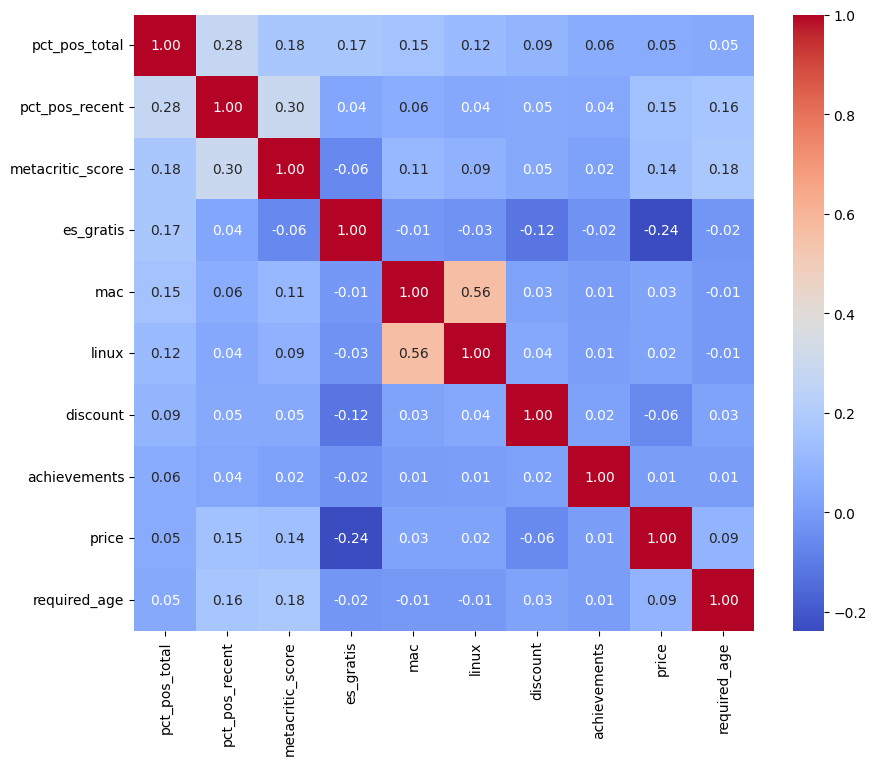

In [ ]:
variable_objetivo = 'pct_pos_total'

df_numerico = df_limpio.select_dtypes(include=['float64', 'int64', 'bool'])

correlaciones = df_numerico.corr()[[variable_objetivo]].sort_values(by=variable_objetivo, ascending=False)

top_variables = correlaciones.abs().head(10).index.tolist()

plt.figure(figsize=(10, 8))
sns.heatmap(df_numerico[top_variables].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

In [ ]:
frecuencia_windows = df_limpio['windows'].value_counts()
porcentaje_windows = df_limpio['windows'].value_counts(normalize=True) * 100

media_score = df_limpio['metacritic_score'].mean()
std_score = df_limpio['metacritic_score'].std()

mediana_precio = df_limpio['price'].median()
q1_precio = df_limpio['price'].quantile(0.25)
q3_precio = df_limpio['price'].quantile(0.75)
iqr_precio = q3_precio - q1_precio
min_precio = df_limpio['price'].min()
max_precio = df_limpio['price'].max()

print(frecuencia_windows, porcentaje_windows)
print(media_score, std_score)
print(mediana_precio, iqr_precio, min_precio, max_precio)

windows
True     89588
False       30
Name: count, dtype: int64 windows
True     99.966525
False     0.033475
Name: proportion, dtype: float64
2.9032448838403 14.445357584354007
4.99 9.0 0.0 999.98


/tmp/ipykernel_7355/1039862992.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_limpio, x='windows', palette='Set2')


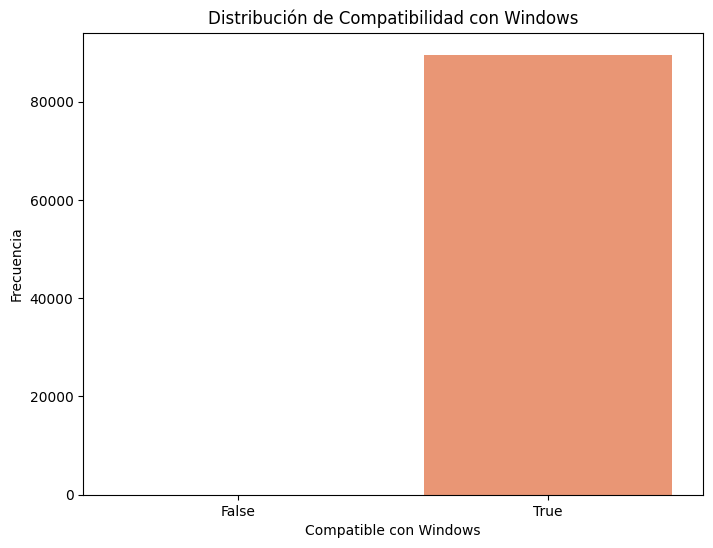

In [ ]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df_limpio, x='windows', palette='Set2')
plt.title('Distribución de Compatibilidad con Windows')
plt.xlabel('Compatible con Windows')
plt.ylabel('Frecuencia')
plt.show()

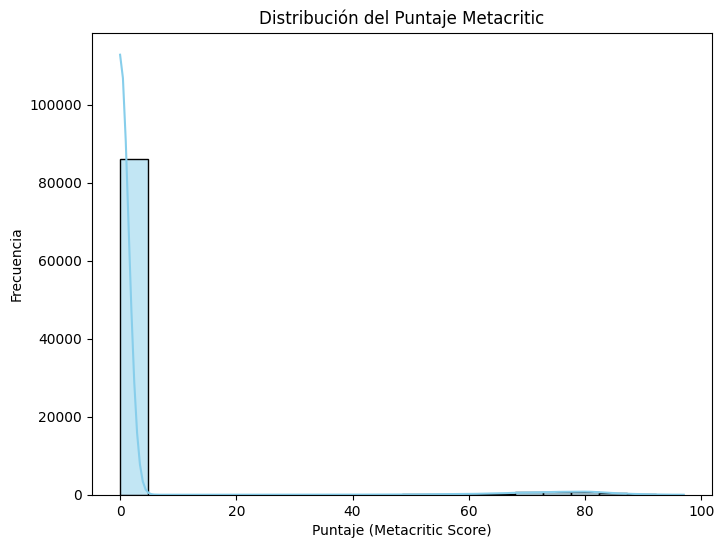

In [ ]:
plt.figure(figsize=(8, 6))
sns.histplot(df_limpio['metacritic_score'], bins=20, kde=True, color='skyblue')
plt.title('Distribución del Puntaje Metacritic')
plt.xlabel('Puntaje (Metacritic Score)')
plt.ylabel('Frecuencia')
plt.show()

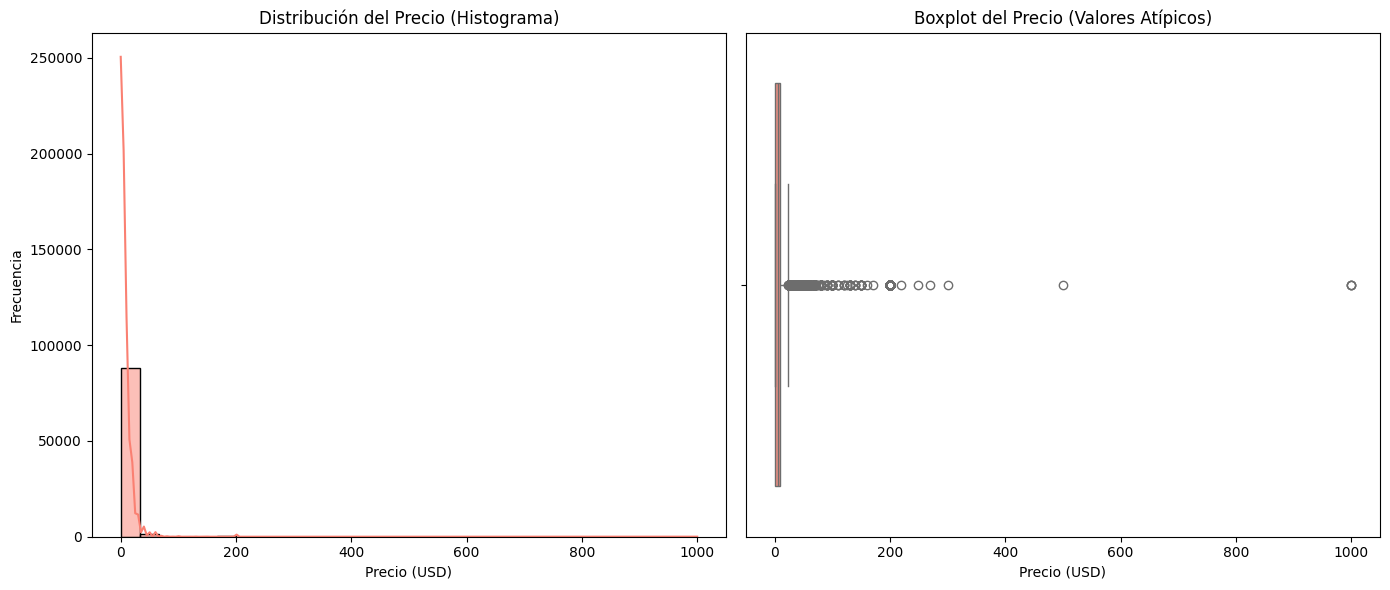

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.histplot(df_limpio['price'], bins=30, kde=True, color='salmon', ax=axes[0])
axes[0].set_title('Distribución del Precio (Histograma)')
axes[0].set_xlabel('Precio (USD)')
axes[0].set_ylabel('Frecuencia')

sns.boxplot(x=df_limpio['price'], color='salmon', ax=axes[1])
axes[1].set_title('Boxplot del Precio (Valores Atípicos)')
axes[1].set_xlabel('Precio (USD)')

plt.tight_layout()
plt.show()

In [ ]:
q1 = df_limpio['price'].quantile(0.25)
q3 = df_limpio['price'].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

df_sin_outliers = df_limpio[df_limpio['price'] <= limite_superior].copy()
juegos_removidos = len(df_limpio) - len(df_sin_outliers)
porcentaje_outliers = (juegos_removidos / len(df_limpio)) * 100

print(limite_superior)
print(porcentaje_outliers)

df_limpio['es_gratis'] = df_limpio['price'] == 0.0

patron_gratis = df_limpio.groupby('es_gratis')['pct_pos_total'].agg(['mean', 'median', 'count'])

print(patron_gratis)

23.490000000000002
4.62630275167935
                mean  median  count
es_gratis                          
False      42.325227    52.0  75458
True       61.484181    75.0  14160


## Conclusiones y Próximos Pasos

**Hallazgos del Análisis Exploratorio (EDA):**
1. **Dimensionalidad y Limpieza:** Se logró reducir significativamente el ruido del dataset eliminando variables con nulos masivos y metadatos irrelevantes, dejando un conjunto robusto de casi 90,000 registros viables.
2. **Distribuciones:** Se identificó que variables clave como el precio presentan una fuerte asimetría positiva, requiriendo técnicas de normalización.
3. **Correlación:** Se seleccionaron las características con mayor impacto directo sobre nuestra variable objetivo (porcentaje de reseñas positivas).

**Plan de Trabajo para Modelado (Próximos Pasos):**
* **Preprocesamiento:** Aplicar técnicas de Escalado (StandardScaler o MinMaxScaler) a las variables numéricas asimétricas para mejorar el rendimiento de los algoritmos.
* **Ingeniería de Características (Feature Engineering):** Convertir las variables categóricas complejas (como los géneros o categorías de Steam) en formatos numéricos mediante técnicas de One-Hot Encoding.
* **Modelado Machine Learning:** Entrenar algoritmos de regresión (ej. Random Forest Regressor o XGBoost) para predecir el éxito (pct_pos_total) de un videojuego en base a sus características antes de su lanzamiento.
https://www.kaggle.com/datasets/artermiloff/steam-games-dataset?resource=download&select=games_march2025_cleaned.csv